# 02 - Modelling, Evaluation, Explainability and Business Value
This notebook **reads the results produced by `python run_pipeline.py`** and walks through them. Run the pipeline first.
It answers: Which model? How good is it? Where is the threshold? What does it mean in money? Why does it flag a customer? Is it fair?

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")            # so `import src...` works from the notebooks/ folder
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200)
from src.config import REPORTS_DIR, FIG_DIR
import joblib
from src.modeling import *   # needed so joblib can load the saved ChurnModel

## 1. Did we meet the BRD targets? (untouched hold-out set)

In [2]:
m = json.load(open(REPORTS_DIR / "metrics.json"))
ci = m["holdout_bootstrap_95ci"]
pd.DataFrame([{"metric": k, "value": round(v["value"], 3), "target": v["target"], "result": "PASS" if v["pass"] else "FAIL",
               "95% CI": [round(x, 3) for x in ci[k]] if k in ci else "-"} for k, v in m["scorecard"].items()])

,metric,value,target,result,95% CI
0,roc_auc,0.844,>= 0.83,PASS,"[0.821, 0.865]"
1,top_decile_lift,2.752,>= 2.5,PASS,"[2.505, 3.077]"
2,recall,0.797,>= 0.7,PASS,"[0.756, 0.835]"
3,precision,0.510,>= 0.5,PASS,"[0.47, 0.551]"
4,net_benefit_vs_random,40624.247,> 0,PASS,-


## 2. Class imbalance: does re-weighting help?

In [3]:
pd.read_csv(REPORTS_DIR / 'imbalance_study.csv').round(4)

,model,class_weights,cv_roc_auc,cv_pr_auc
0,logistic_regression,False,0.8469,0.6629
1,logistic_regression,True,0.8468,0.6611
2,random_forest,False,0.8458,0.6614
3,random_forest,True,0.8459,0.6607
4,xgboost,False,0.8448,0.6590
5,xgboost,True,0.8447,0.6587


Class weights barely change **ranking** quality (ROC-AUC/PR-AUC). Their real effect is on the raw probability scale, which is why we **calibrate** probabilities and then choose the threshold explicitly.

## 3. Model comparison (5-fold CV on training data)

In [4]:
pd.read_csv(REPORTS_DIR / 'model_comparison_cv.csv').round(4)

,model,cv_roc_auc,cv_roc_auc_std,cv_pr_auc,best_params
0,logistic_regression,0.8469,0.0121,0.6615,{'C': np.float64(0.0315)}
1,random_forest,0.8475,0.0101,0.6617,"{'max_depth': 6, 'max_features': 0.3, 'min_sam..."
2,xgboost,0.8485,0.0112,0.6664,"{'colsample_bytree': np.float64(0.9436), 'lear..."


All three models are within about 0.002 ROC-AUC of each other. We pick the **simplest model within 0.003 of the best** (logistic regression): the dataset is small, the linear model is easier to explain and less likely to overfit.
The advanced models are not wasted - they prove that extra complexity buys nothing here.

## 4. Threshold selection (BR-04)

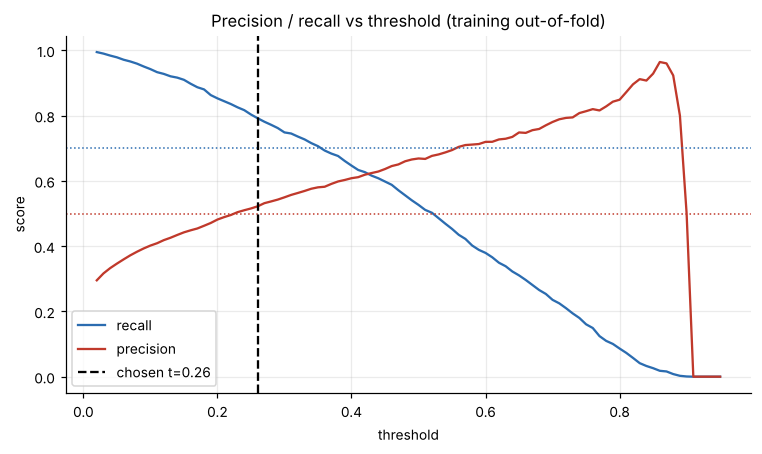

{'t_cost': 0.08, 't_op': 0.26, 'note': 'recall/precision targets met with margin 0.02', 'feasible_range': [0.26, 0.33]}


In [5]:
display(Image(FIG_DIR / 'threshold_tradeoff.png')); print(m['thresholds'])

* **t_cost** = threshold with the highest simulated profit (very low, because one saved customer is worth far more than a $20 offer).
* **t_op** = highest profit **among thresholds that also give recall >= 0.70 and precision >= 0.50** (the BRD acceptance criteria). It defines the High tier.

## 5. Hold-out performance

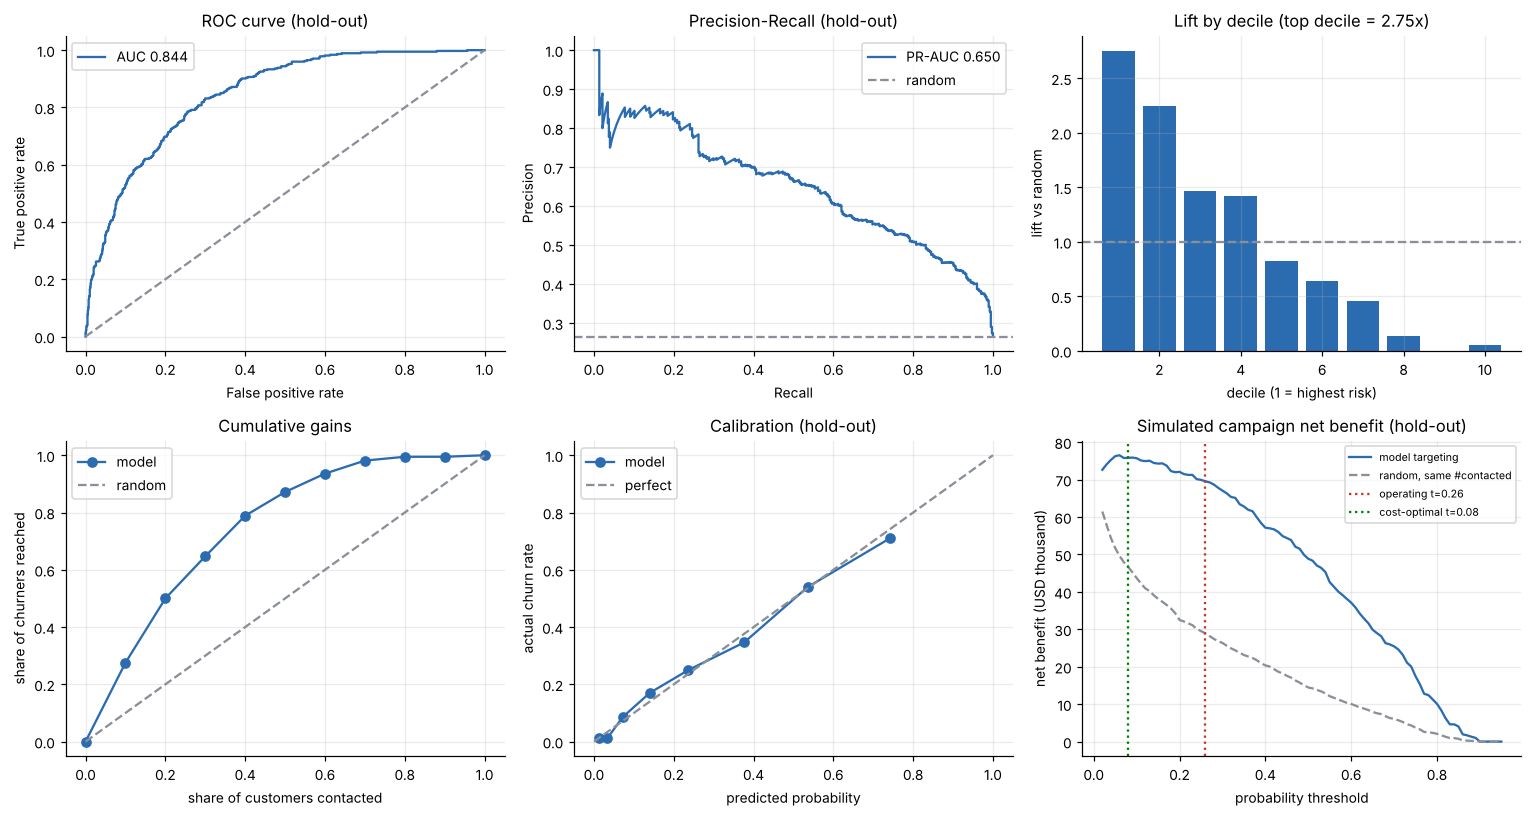

In [6]:
display(Image(FIG_DIR / 'model_performance.png'))

In [7]:
pd.read_csv(REPORTS_DIR / 'lift_table_holdout.csv').round(3)

,decile,customers,churners,avg_prob,churn_rate,lift,cum_churners_captured
0,1,141,103,0.764,0.730,2.752,0.275
1,2,141,84,0.592,0.596,2.244,0.500
2,3,141,55,0.452,0.390,1.470,0.647
3,4,141,53,0.331,0.376,1.416,0.789
4,5,141,31,0.223,0.220,0.828,0.872
5,6,141,24,0.148,0.170,0.641,0.936
6,7,141,17,0.088,0.121,0.454,0.981
7,8,141,5,0.048,0.035,0.134,0.995
8,9,141,0,0.026,0.000,0.000,0.995
9,10,140,2,0.011,0.014,0.054,1.000


## 6. Business value (simulated campaign)

In [8]:
cb = m["cost_benefit_holdout"]
pd.DataFrame({k: cb[k] for k in ["operating", "cost_optimal"]}).T.round(0)

,threshold,customers_contacted,campaign_cost,net_benefit_model,net_benefit_random_same_budget,uplift_vs_random
operating,0.0,584.0,11680.0,69552.0,28928.0,40624.0
cost_optimal,0.0,942.0,18840.0,75812.0,46661.0,29151.0


In [9]:
print('Contact EVERYONE net benefit:', round(cb['contact_everyone']['net_benefit']))
pd.read_csv(REPORTS_DIR / 'cost_benefit_sensitivity.csv').round(0)

Contact EVERYONE net benefit: 69794


,offer_cost,success_rate,contact_everyone,random_same_count_as_high_tier,high_tier_only,model_expected_value_rule,n_contacted_ev_rule
0,20,0.0,4478.0,1856.0,15397.0,15778.0,572
1,20,0.0,37136.0,15392.0,42475.0,45713.0,775
2,20,0.0,69794.0,28928.0,69552.0,77054.0,859
3,50,0.0,-37792.0,-15664.0,-2123.0,4072.0,279
4,50,0.0,-5134.0,-2128.0,24955.0,25899.0,505
5,50,0.0,27524.0,11408.0,52032.0,53691.0,632
6,100,0.0,-108242.0,-44864.0,-31323.0,146.0,7
7,100,0.0,-75584.0,-31328.0,-4245.0,8144.0,279
8,100,0.0,-42926.0,-17792.0,22832.0,27735.0,422
9,150,0.0,-178692.0,-74064.0,-60523.0,0.0,0


**Important:** at the BRD's assumptions (offer cost 20 USD vs customer value of about 780 USD) contacting everyone is almost as profitable as contacting the High tier. The model's value is spending much less for nearly the same result, handling limited call capacity, and staying profitable when offers cost more (see the sensitivity table).

## 7. Are the risk tiers meaningful?

In [10]:
pd.read_csv(REPORTS_DIR / 'risk_tier_validation_holdout.csv').round(3)

,risk_tier,customers,actual_churn_rate,avg_predicted
0,High,584,0.510,0.526
1,Medium,358,0.176,0.157
2,Low,467,0.028,0.033


## 8. Explainability (SHAP)

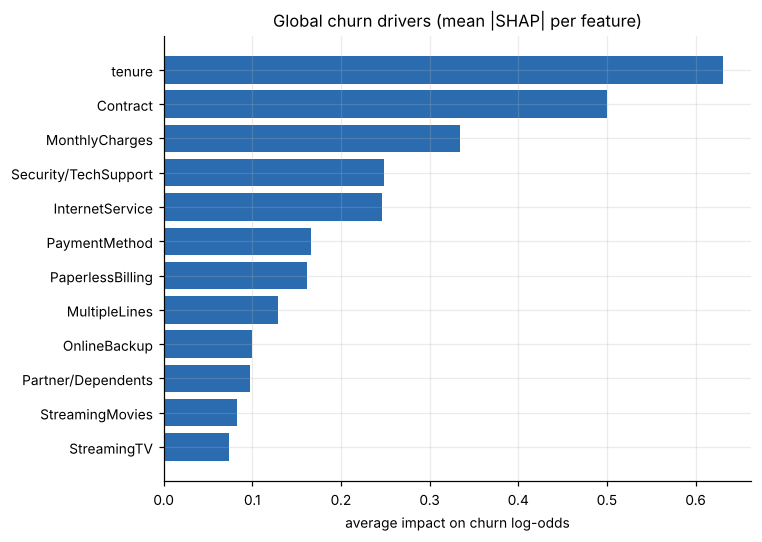

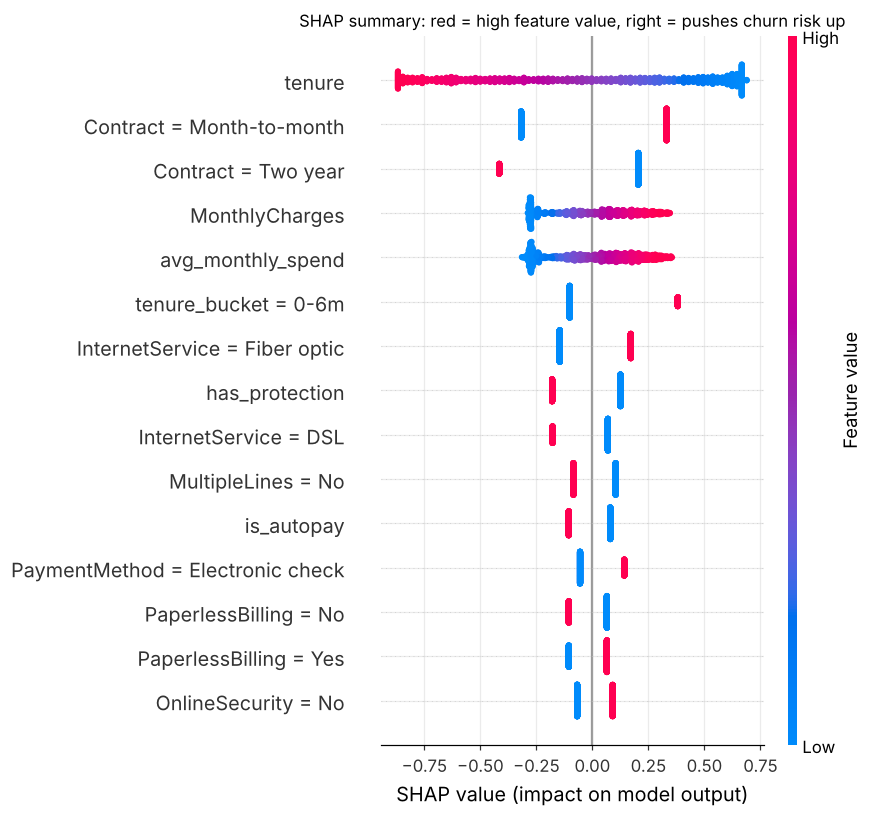

In [11]:
display(Image(FIG_DIR / 'shap_global_importance.png')); display(Image(FIG_DIR / 'shap_beeswarm.png'))

In [12]:
s = pd.read_csv(REPORTS_DIR / "scored_customers.csv")
s[["customerID", "churn_probability", "risk_tier", "driver_1", "driver_2", "driver_3"]].head(8)

,customerID,churn_probability,risk_tier,driver_1,driver_2,driver_3
0,7216-EWTRS,0.8950,High,tenure = 1 months,Contract = Month-to-month,MonthlyCharges = $100.80
1,5150-ITWWB,0.8947,High,tenure = 3 months,Contract = Month-to-month,MonthlyCharges = $94.85
2,5178-LMXOP,0.8945,High,tenure = 1 months,Contract = Month-to-month,MonthlyCharges = $95.10
3,5419-JPRRN,0.8932,High,tenure = 1 months,Contract = Month-to-month,MonthlyCharges = $101.45
4,0295-PPHDO,0.8923,High,tenure = 1 months,Contract = Month-to-month,MonthlyCharges = $95.45
5,6023-YEBUP,0.8919,High,tenure = 3 months,Contract = Month-to-month,MonthlyCharges = $100.95
6,4910-GMJOT,0.8912,High,tenure = 1 months,Contract = Month-to-month,MonthlyCharges = $94.60
7,7851-WZEKY,0.8910,High,tenure = 2 months,Contract = Month-to-month,MonthlyCharges = $95.15


## 9. Fairness check (BR-06)

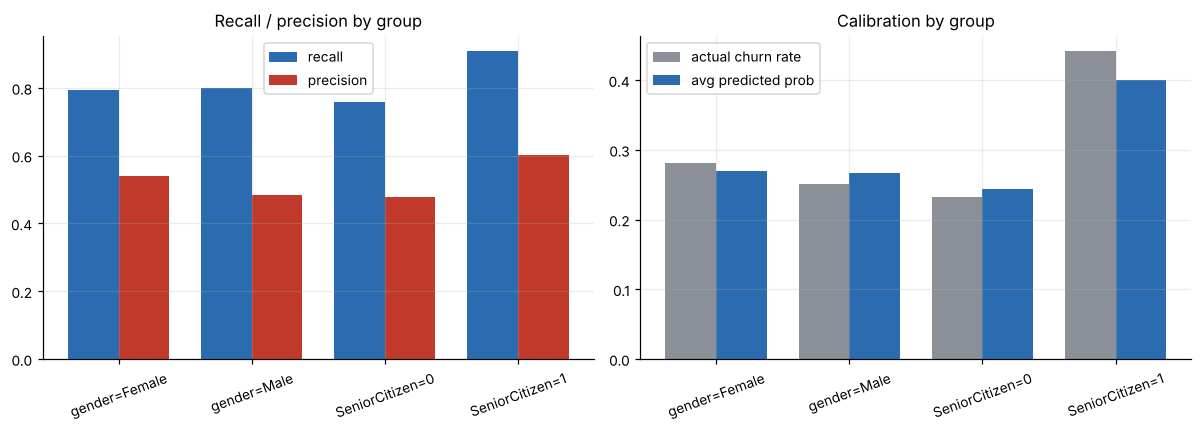

,attribute,group,customers,actual_churn_rate,avg_predicted_prob,roc_auc,recall_tpr,precision,false_positive_rate,flag_rate
0,gender,Female,687,0.281,0.270,0.840,0.793,0.539,0.265,0.413
1,gender,Male,722,0.251,0.267,0.848,0.801,0.483,0.287,0.416
2,SeniorCitizen,0,1187,0.233,0.244,0.846,0.757,0.479,0.249,0.367
3,SeniorCitizen,1,222,0.441,0.400,0.779,0.908,0.601,0.476,0.667


In [13]:
display(Image(FIG_DIR / 'fairness_by_group.png')); pd.read_csv(REPORTS_DIR / 'fairness_by_group.csv').round(3)

## 10. Use the saved model on a brand-new customer

In [14]:
model = joblib.load("../models/churn_model.joblib")
new = pd.DataFrame([{
    "customerID": "NEW-0001", "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 3,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic", "OnlineSecurity": "No",
    "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes", "StreamingMovies": "Yes",
    "Contract": "Month-to-month", "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 95.0, "TotalCharges": 285.0}])
p = model.predict_proba(new)
print(f"churn probability = {p[0]:.1%}  ->  risk tier: {model.risk_tier(p)[0]}")

churn probability = 85.9%  ->  risk tier: High
